# Part A: Demand Forecast
### DADS5250 Hackathon — Boston 311 Staffing and Intake Assistant

**Author:** Charlotte Sy

## Objective

Forecast monthly 311 service request demand for four Boston city departments
for 2025 using historical request data from 2023 and 2024.

Departments:
- PWDx — Public Works
- BTDT — Transportation
- PARK — Parks and Recreation
- ISD — Inspectional Services

## Methodology

The forecast uses monthly seasonal averages from 2023 and 2024,
adjusted by each department's year-over-year growth rate.

## Deliverables

1. Monthly request counts for 2023 and 2024.
2. Department-level growth rates.
3. Monthly demand forecasts for 2025.
4. Backtesting and average percentage error.
5. Forecast visualizations.

In [1]:
# ==========================================================
# Step 1: Import libraries and connect to LanceDB
# ==========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lancedb

# Locate the project directory automatically
current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder for folder in [current_path, *current_path.parents]
        if (folder / "data" / "lancedb").exists()
    ),
    None
)

# Stop if the project folder cannot be found
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Open the notebook from within the project."
    )

# Connect to the existing LanceDB database
DB_PATH = PROJECT_ROOT / "data" / "lancedb"

db = lancedb.connect(DB_PATH)

# Verify database connection
print("Database location:", DB_PATH)
print("Available tables:", db.list_tables().tables)

assert "requests" in db.list_tables().tables, (
    "The requests table was not found. Check DB_PATH."
)

print("\nDatabase connection successful!")

Database location: /Users/charlottesy/Documents/dads5250-311-intake-assistant/data/lancedb
Available tables: ['intake_eval', 'request_types', 'requests', 'type_aliases']

Database connection successful!


## 1. Data Loading and Exploration

This section loads historical Boston 311 service request data from the existing LanceDB `requests` table.

The dataset is inspected to verify the total number of requests, available columns, departments, and date range before performing the demand forecasting analysis.

In [2]:
# ==========================================================
# Step 2: Load and inspect historical request data
# ==========================================================

# Load the requests table from LanceDB
requests = db.open_table("requests").to_pandas()

# Convert the opening date to datetime
requests["open_dt"] = pd.to_datetime(requests["open_dt"])

# Inspect the dataset
print("Total requests:", len(requests))

print("\nAvailable columns:")
print(requests.columns.tolist())

print("\nRequests by department:")
print(requests["department"].value_counts())

print("\nDate range:")
print("Earliest:", requests["open_dt"].min())
print("Latest:", requests["open_dt"].max())

# Preview the first five rows
display(requests.head())

Total requests: 558663

Available columns:
['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt', 'on_time', 'case_status', 'case_title', 'subject', 'reason', 'type', 'queue', 'department', 'neighborhood', 'source', 'open_month', 'has_sla', 'sla_days', 'is_employee']

Requests by department:
department
PWDx    328878
BTDT    156761
ISD      36747
PARK     36277
Name: count, dtype: int64

Date range:
Earliest: 2023-01-01 00:11:22.940000
Latest: 2024-12-31 23:47:03.657000


,case_enquiry_id,open_dt,sla_target_dt,closed_dt,on_time,case_status,case_title,subject,reason,type,queue,department,neighborhood,source,open_month,has_sla,sla_days,is_employee
0,101004616857,2023-01-02 15:50:52.307,2023-01-04 08:30:00.000,2023-01-03 09:41:31.773,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated,2023-01-01,True,1.693839,True
1,101004617727,2023-01-03 11:37:13.827,2023-01-04 11:37:14.000,2023-01-03 12:14:52.223,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated,2023-01-01,True,1.000002,True
2,101004620394,2023-01-05 09:51:54.313,2023-01-06 09:51:55.610,2023-01-05 15:11:48.023,ONTIME,Closed,Traffic Signal Inspection,Transportation - Traffic Division,Signs & Signals,Traffic Signal Inspection,BTDT Traffic Signal Repair,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,1.000015,False
3,101004621762,2023-01-06 11:20:53.710,2023-01-09 11:20:55.000,2023-01-07 06:30:08.457,ONTIME,Closed,Empty Litter Basket,Public Works Department,Highway Maintenance,Empty Litter Basket,PWDx District 10A: Roxbury,PWDx,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,3.000015,False
4,101004622259,2023-01-06 15:57:07.403,2023-01-09 15:57:08.000,2023-01-06 17:48:32.340,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT Parking Enforcement,BTDT,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App,2023-01-01,True,3.000007,False


## Step 3: Calculate Monthly Request Counts (2023–2024)

This section calculates the total number of Boston 311 service requests submitted each month for each department.

The monthly counts will be used to calculate department-level growth rates, generate the 2025 demand forecasts, and evaluate forecasting accuracy through backtesting.

In [3]:
# ==========================================================
# Step 3: Calculate monthly request counts (2023–2024)
# ==========================================================

# Create year and month columns from the request opening date
requests["year"] = requests["open_dt"].dt.year
requests["month"] = requests["open_dt"].dt.month

# Count requests by department, year, and month
monthly_counts = (
    requests.groupby(["department", "year", "month"])
    .size()
    .reset_index(name="request_count")
    .sort_values(["department", "year", "month"])
    .reset_index(drop=True)
)

# Verify the expected number of rows
print("Total monthly records:", len(monthly_counts))

# Verify the total number of requests
print("Total requests counted:", monthly_counts["request_count"].sum())

# Display monthly counts
display(monthly_counts)

Total monthly records: 96
Total requests counted: 558663


,department,year,month,request_count
0,BTDT,2023,1,5692
1,BTDT,2023,2,5316
2,BTDT,2023,3,6889
3,BTDT,2023,4,6143
4,BTDT,2023,5,6737
...,...,...,...,...
91,PWDx,2024,8,16398
92,PWDx,2024,9,15912
93,PWDx,2024,10,11639
94,PWDx,2024,11,10172


### NOTE: Monthly Request Count Validation

The dataset contains 96 monthly records, calculated as:

$$
4 \text{ departments} \times 2 \text{ years} \times 12 \text{ months} = 96 \text{ records}
$$

Each department has 24 monthly observations covering January 2023 through December 2024.

The total monthly request counts should equal the original dataset total of 558,663 requests, confirming that all historical requests are accounted for in the aggregation.

## Step 4: Calculate Department-Level Growth Rates

This section calculates the annual growth rate for each department by comparing total service requests in 2023 and 2024.

The growth rate measures the percentage change in request volume between the two years and will be used to adjust the seasonal averages when forecasting demand for 2025.

The growth rate is calculated as:

$$
\text{Growth Rate} = \frac{\text{2024 Requests} - \text{2023 Requests}}{\text{2023 Requests}}
$$

A positive growth rate indicates an increase in service requests, while a negative growth rate indicates a decrease.

In [4]:
# ==========================================================
# Step 4: Calculate department-level growth rates
# ==========================================================

# Calculate annual request totals for each department
annual_counts = (
    monthly_counts.groupby(["department", "year"])["request_count"]
    .sum()
    .unstack("year")
)

# Rename columns for clarity
annual_counts = annual_counts.rename(
    columns={2023: "requests_2023", 2024: "requests_2024"}
)

# Calculate growth rate from 2023 to 2024
annual_counts["growth_rate"] = (
    (annual_counts["requests_2024"] - annual_counts["requests_2023"])
    / annual_counts["requests_2023"]
)

# Convert growth rate to a percentage for easier interpretation
annual_counts["growth_rate_pct"] = (
    annual_counts["growth_rate"] * 100
)

# Display results
print("Department-Level Annual Growth Rates (2023–2024):")

display(annual_counts.round(2))

Department-Level Annual Growth Rates (2023–2024):


year,requests_2023,requests_2024,growth_rate,growth_rate_pct
department,,,,
BTDT,75314,81447,0.08,8.14
ISD,18123,18624,0.03,2.76
PARK,17541,18736,0.07,6.81
PWDx,171268,157610,-0.08,-7.97


In [5]:
# Calculate total requests across all departments for each year
total_2023 = annual_counts["requests_2023"].sum()
total_2024 = annual_counts["requests_2024"].sum()

# Calculate overall growth rate
overall_growth_rate = (
    (total_2024 - total_2023) / total_2023
) * 100

# Display totals and overall growth rate
print("\nOverall Request Totals:")
print(f"2023 Total Requests: {total_2023:,}")
print(f"2024 Total Requests: {total_2024:,}")
print(f"Combined Requests: {total_2023 + total_2024:,}")
print(f"Overall Growth Rate: {overall_growth_rate:.2f}%")


Overall Request Totals:
2023 Total Requests: 282,246
2024 Total Requests: 276,417
Combined Requests: 558,663
Overall Growth Rate: -2.07%


### Department-Level Growth Rate Analysis

The annual growth rates were calculated by comparing total service requests in 2023 and 2024 for each department.

Three departments experienced an increase in request volume:

- **BTDT:** 8.14% increase
- **ISD:** 2.76% increase
- **PARK:** 6.81% increase

**PWDx** experienced a 7.97% decrease in request volume.

Overall, total requests decreased from 282,246 in 2023 to 276,417 in 2024, representing an approximately 2.07% decline.

These department-level growth rates will be used as adjustment factors when generating the 2025 monthly demand forecasts.

# Step 5: Generate Monthly Demand Forecasts for 2025

This section generates monthly service request forecasts for 2025 using historical request counts from 2023 and 2024.

The forecasting method combines two components:

1. **Seasonal Average:** The average number of requests received during the same month in 2023 and 2024.
2. **Department-Level Growth Factor:** The annual growth rate calculated for each department in Step 4.

The seasonal average is calculated as:

$$
\text{Seasonal Average} = \frac{\text{2023 Monthly Requests} + \text{2024 Monthly Requests}}{2}
$$

The 2025 forecast is then calculated as:

$$
\text{2025 Forecast} = \text{Seasonal Average} \times (1 + \text{Department Growth Rate})
$$

This method accounts for historical monthly demand patterns while adjusting for changes in annual request volume.

The resulting forecast will contain 48 rows:

$$
4 \text{ departments} \times 12 \text{ months} = 48 \text{ forecasts}
$$

In [6]:
# ==========================================================
# Step 5: Generate monthly demand forecasts for 2025
# ==========================================================

# Reshape monthly counts to compare 2023 and 2024 side by side
monthly_comparison = (
    monthly_counts
    .pivot(
        index=["department", "month"],
        columns="year",
        values="request_count"
    )
    .reset_index()
)

# Rename columns for clarity
monthly_comparison = monthly_comparison.rename(
    columns={
        2023: "requests_2023",
        2024: "requests_2024"
    }
)

# Calculate seasonal average for each department and month
monthly_comparison["seasonal_average"] = (
    monthly_comparison["requests_2023"]
    + monthly_comparison["requests_2024"]
) / 2

# Add department-level growth rates from Step 4
monthly_comparison = monthly_comparison.merge(
    annual_counts[["growth_rate"]],
    left_on="department",
    right_index=True,
    how="left",
    validate="many_to_one"
)

# Calculate 2025 monthly demand forecasts
monthly_comparison["forecast_2025"] = (
    monthly_comparison["seasonal_average"]
    * (1 + monthly_comparison["growth_rate"])
)

# Round forecasts to whole requests
monthly_comparison["forecast_2025"] = (
    monthly_comparison["forecast_2025"]
    .round()
    .astype(int)
)

# Create the final forecast table
forecast_2025 = monthly_comparison[
    [
        "department",
        "month",
        "requests_2023",
        "requests_2024",
        "seasonal_average",
        "growth_rate",
        "forecast_2025"
    ]
].copy()

# Sort by department and month
forecast_2025 = forecast_2025.sort_values(
    ["department", "month"]
).reset_index(drop=True)

# Verify forecast results
print("Total forecast rows:", len(forecast_2025))
print("Departments:", forecast_2025["department"].nunique())
print("Months per department:")
print(forecast_2025.groupby("department")["month"].nunique())

# Verify that no forecast values are missing
assert len(forecast_2025) == 48, "Expected 48 forecast rows."
assert forecast_2025["forecast_2025"].notna().all(), (
    "Missing forecast values detected."
)

# Display forecast table
display(forecast_2025)

Total forecast rows: 48
Departments: 4
Months per department:
department
BTDT    12
ISD     12
PARK    12
PWDx    12
Name: month, dtype: int64


year,department,month,requests_2023,requests_2024,seasonal_average,growth_rate,forecast_2025
0,BTDT,1,5692,5620,5656.0,0.081432,6117
1,BTDT,2,5316,5954,5635.0,0.081432,6094
2,BTDT,3,6889,7209,7049.0,0.081432,7623
3,BTDT,4,6143,7008,6575.5,0.081432,7111
4,BTDT,5,6737,7511,7124.0,0.081432,7704
5,BTDT,6,6682,7176,6929.0,0.081432,7493
6,BTDT,7,5517,6678,6097.5,0.081432,6594
7,BTDT,8,6473,6719,6596.0,0.081432,7133
8,BTDT,9,7190,7633,7411.5,0.081432,8015
9,BTDT,10,7018,7675,7346.5,0.081432,7945


### 2025 Monthly Demand Forecast Validation

The forecasting process generated 48 monthly demand predictions for 2025, covering all four departments (BTDT, ISD, PARK, and PWDx).

Each department contains 12 monthly forecasts, representing January through December 2025.

The forecasts were calculated using the average monthly request volume from 2023 and 2024, adjusted by each department's annual growth rate.

For example, the January 2025 forecast for BTDT was calculated as follows:

**January 2023 Requests:** 5,692

**January 2024 Requests:** 5,620

**BTDT Annual Growth Rate:** 8.14%

**Step 1: Calculate the seasonal average**

$$
\frac{5692+5620}{2}=5656
$$

**Step 2: Apply the department growth factor**

$$
5656\times(1+0.081432)\approx6117
$$

The predicted number of BTDT service requests for January 2025 is approximately **6,117 requests**.

This approach preserves historical monthly demand patterns while accounting for department-level changes in annual request volume.

The resulting forecasts will be evaluated through backtesting against actual 2024 request counts in the next section.

# Step 6: Backtesting Against 2024

This section checks how accurate our forecasting approach is by comparing predicted requests for 2024 with the actual number of requests received.

Since we only have data from 2023 and 2024, we’ll use the monthly request counts from 2023 to predict the same months in 2024.

For example, January 2023 requests will be used to predict January 2024 requests.

The prediction is calculated as:

$$
\text{Predicted 2024 Requests} = \text{Actual 2023 Requests}
$$

To measure accuracy, we’ll calculate the percentage difference between the predicted and actual requests:

$$
\text{Percentage Error} = \frac{|\text{Actual} - \text{Predicted}|}{\text{Actual}} \times 100
$$

We’ll then calculate the average percentage error across all 12 months for each department.

A lower average percentage error means the predictions were closer to the actual request counts.

Note: This backtest uses 2023 monthly requests as a baseline rather than the growth-adjusted method used for the 2025 forecasts, since we don’t have data from before 2023 to calculate an earlier growth rate.

In [7]:
# ==========================================================
# Step 6: Backtesting against actual 2024 requests
# ==========================================================

# Create backtesting dataset
backtest_2024 = monthly_comparison[
    ["department", "month", "requests_2023", "requests_2024"]
].copy()

# Use 2023 monthly requests to predict 2024
backtest_2024["predicted_2024"] = (
    backtest_2024["requests_2023"]
)

# Calculate absolute percentage error for each month
backtest_2024["absolute_percentage_error"] = (
    abs(
        backtest_2024["requests_2024"]
        - backtest_2024["predicted_2024"]
    )
    / backtest_2024["requests_2024"]
) * 100

# Calculate average percentage error for each department
backtest_summary = (
    backtest_2024
    .groupby("department")["absolute_percentage_error"]
    .mean()
    .reset_index(name="MAPE_percent")
)

# Validate backtesting results
assert len(backtest_2024) == 48, "Expected 48 backtesting records."
assert (backtest_2024["requests_2024"] > 0).all(), (
    "MAPE requires nonzero actual request counts."
)

print("Backtesting Results: Monthly Predictions vs Actual 2024")
display(backtest_2024.round(2))

print("\nAverage Percentage Error by Department:")
display(backtest_summary.round(2))

Backtesting Results: Monthly Predictions vs Actual 2024


year,department,month,requests_2023,requests_2024,predicted_2024,absolute_percentage_error
0,BTDT,1,5692,5620,5692,1.28
1,BTDT,2,5316,5954,5316,10.72
2,BTDT,3,6889,7209,6889,4.44
3,BTDT,4,6143,7008,6143,12.34
4,BTDT,5,6737,7511,6737,10.30
5,BTDT,6,6682,7176,6682,6.88
6,BTDT,7,5517,6678,5517,17.39
7,BTDT,8,6473,6719,6473,3.66
8,BTDT,9,7190,7633,7190,5.80
9,BTDT,10,7018,7675,7018,8.56



Average Percentage Error by Department:


,department,MAPE_percent
0,BTDT,7.64
1,ISD,13.33
2,PARK,17.73
3,PWDx,13.59


### Backtesting Results and Analysis

The backtesting results compare predicted monthly requests for 2024 against the actual 2024 request counts.

The Mean Absolute Percentage Error (MAPE) for each department was:

- **BTDT:** 7.64%
- **ISD:** 13.33%
- **PARK:** 17.73%
- **PWDx:** 13.59%

BTDT had the lowest average forecasting error at 7.64%, meaning its monthly request counts were relatively close to the previous year's values.

PARK had the highest average forecasting error at 17.73%, indicating greater differences between its 2023 and 2024 monthly request counts.

ISD and PWDx had similar average errors of approximately 13%.

Overall, the results show that forecasting accuracy varies by department.

**Limitation:** Because only 2023 and 2024 data are available, this backtest uses 2023 monthly counts to predict 2024. Therefore, these results evaluate a simple seasonal baseline rather than the growth-adjusted forecasting method used for 2025.

# Step 7: Visualize Monthly Demand Forecasts

This section compares historical monthly request counts from 2023 and 2024 with the predicted demand for 2025.

A separate line chart is created for each department (BTDT, ISD, PARK, and PWDx).

Each chart displays:
- **2023 Actual:** Monthly service requests received in 2023.
- **2024 Actual:** Monthly service requests received in 2024.
- **2025 Forecast:** Predicted monthly requests based on seasonal averages and department growth rates.

These visualizations help identify seasonal patterns and differences between historical and forecasted demand.

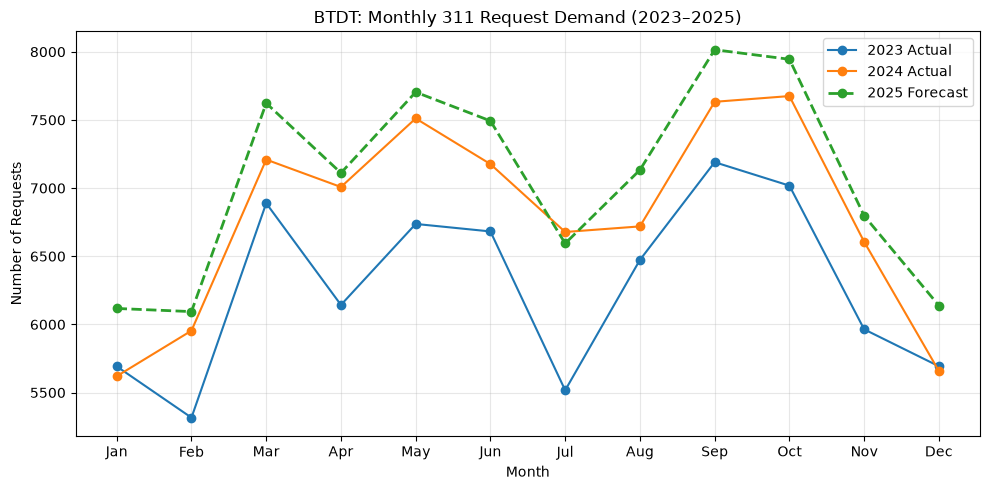

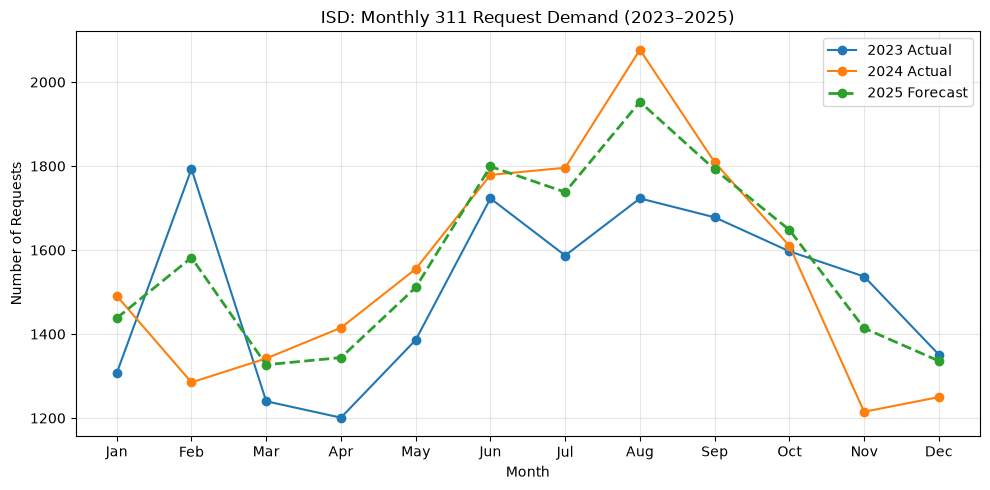

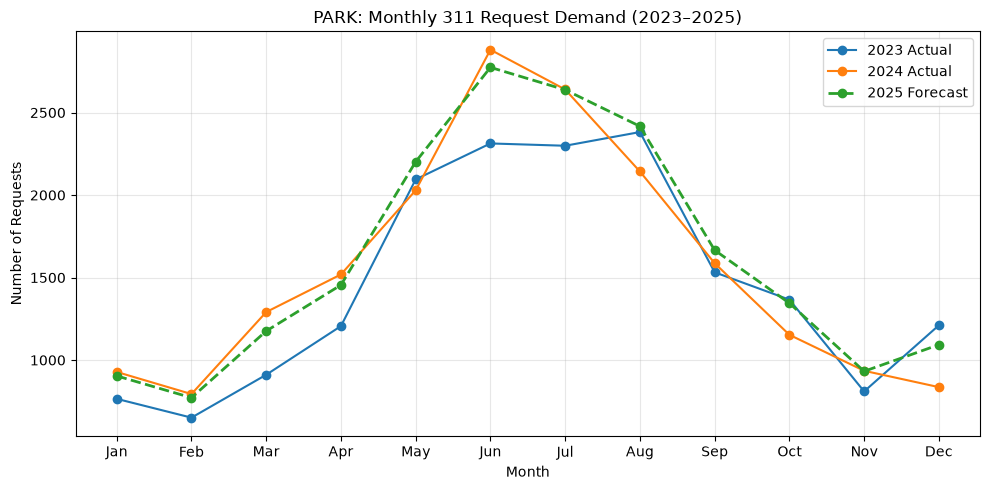

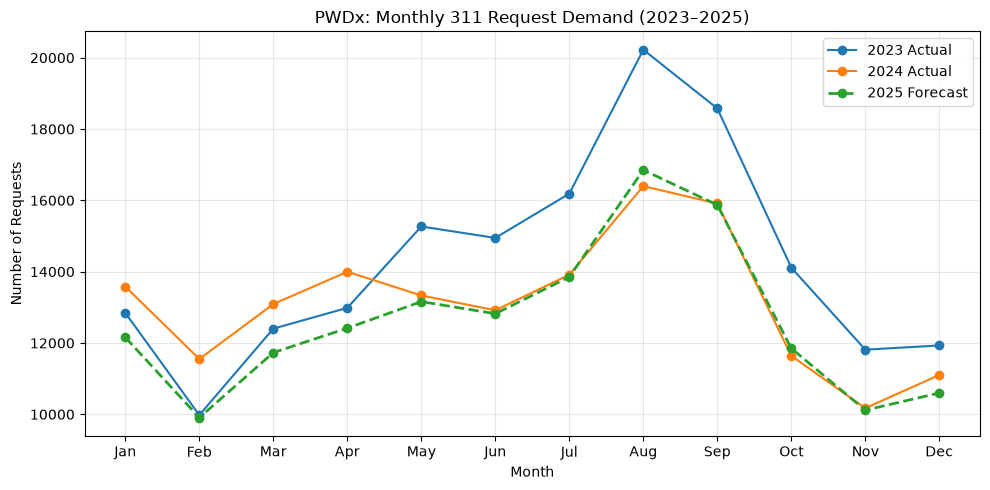

In [8]:
# ==========================================================
# Step 7: Visualize monthly demand forecasts (2023–2025)
# ==========================================================

# Month labels for the x-axis
month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Create a separate line chart for each department
departments = ["BTDT", "ISD", "PARK", "PWDx"]

for dept in departments:

    # Filter data for the current department
    dept_data = forecast_2025[
        forecast_2025["department"] == dept
    ].sort_values("month")

    # Create chart
    plt.figure(figsize=(10, 5))

    # Plot actual 2023 requests
    plt.plot(
        dept_data["month"],
        dept_data["requests_2023"],
        marker="o",
        label="2023 Actual"
    )

    # Plot actual 2024 requests
    plt.plot(
        dept_data["month"],
        dept_data["requests_2024"],
        marker="o",
        label="2024 Actual"
    )

    # Plot forecasted 2025 requests
    plt.plot(
        dept_data["month"],
        dept_data["forecast_2025"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="2025 Forecast"
    )

    # Chart formatting
    plt.title(f"{dept}: Monthly 311 Request Demand (2023–2025)")
    plt.xlabel("Month")
    plt.ylabel("Number of Requests")

    plt.xticks(range(1, 13), month_labels)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

### Results and Analysis

The four charts compare the actual monthly requests from 2023 and 2024 with the predicted requests for 2025.

**Key Observations:**

- **BTDT:** Requests increased from 2023 to 2024. The 2025 forecast shows higher demand around September and October.
- **ISD:** Requests change throughout the year, with higher demand during the summer months.
- **PARK:** Requests are generally higher during the spring and summer and lower toward the end of the year.
- **PWDx:** Requests decreased from 2023 to 2024. The 2025 forecast reflects this decrease.

**Overall Results:**

The charts show that each department has different monthly demand patterns. BTDT, ISD, and PARK had an overall increase in requests, while PWDx had a decrease.

The 2025 forecasts use the monthly averages from 2023 and 2024, along with each department's growth rate, to estimate future requests.

# Step 8: Export and Validate Final Results

This section saves the final 2025 demand forecast as a CSV file so it can be used by other parts of the project.

The final forecast includes:
- Department
- Month
- Predicted number of requests for 2025

Before saving, the data is checked to make sure all four departments have 12 months of predictions, for a total of 48 rows.

In [9]:
# ==========================================================
# Step 8: Export and validate final 2025 demand forecast
# ==========================================================

# Select the columns needed for the final forecast
final_forecast = forecast_2025[
    ["department", "month", "forecast_2025"]
].copy()

# Sort by department and month
final_forecast = final_forecast.sort_values(
    ["department", "month"]
).reset_index(drop=True)

# Check that the forecast has 48 rows
assert len(final_forecast) == 48, "Expected 48 forecast rows."

# Check that there are 4 departments
assert final_forecast["department"].nunique() == 4, \
    "Expected 4 departments."

# Check that each department has 12 months
assert (
    final_forecast.groupby("department")["month"].nunique() == 12
).all(), "Each department must have 12 months."

# Check for missing or negative forecast values
assert final_forecast["forecast_2025"].notna().all(), \
    "Forecast contains missing values."

assert (final_forecast["forecast_2025"] >= 0).all(), \
    "Forecast contains negative values."

# Create an outputs folder in the project
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the forecast as a CSV file
forecast_file = OUTPUT_DIR / "demand_forecast_2025.csv"

final_forecast.to_csv(forecast_file, index=False)

# Display the results
print("Forecast validation passed!")
print(f"Total forecast rows: {len(final_forecast)}")
print(f"Departments: {final_forecast['department'].nunique()}")
print(f"CSV saved to: {forecast_file}")

display(final_forecast)

Forecast validation passed!
Total forecast rows: 48
Departments: 4
CSV saved to: /Users/charlottesy/Documents/dads5250-311-intake-assistant/outputs/demand_forecast_2025.csv


year,department,month,forecast_2025
0,BTDT,1,6117
1,BTDT,2,6094
2,BTDT,3,7623
3,BTDT,4,7111
4,BTDT,5,7704
5,BTDT,6,7493
6,BTDT,7,6594
7,BTDT,8,7133
8,BTDT,9,8015
9,BTDT,10,7945


In [10]:
# ==========================================================
# Step 8: Export backtesting results
# ==========================================================

# Save the backtesting summary as a CSV file
backtest_file = OUTPUT_DIR / "demand_backtest_2024.csv"

backtest_summary.to_csv(backtest_file, index=False)

# Confirm the file was saved
print("Backtesting results saved!")
print(f"CSV saved to: {backtest_file}")

# Display the results
display(backtest_summary.round(2))

Backtesting results saved!
CSV saved to: /Users/charlottesy/Documents/dads5250-311-intake-assistant/outputs/demand_backtest_2024.csv


,department,MAPE_percent
0,BTDT,7.64
1,ISD,13.33
2,PARK,17.73
3,PWDx,13.59
